### Project Overview: Predicting TV Series Season 1 Cancellation

* **Objective:** Build a predictive machine learning pipeline to determine whether a TV series will be canceled after its first season (`is_canceled = 1`) or renewed (`is_canceled = 0`).
* **Data Sources:** 
  * **IMDb Datasets:** `title.basics`, `title.episode`, and `title.ratings` for foundational metadata and Season 1 voting behavior.
  * **TMDB Dataset:** Supplementary features, network identifiers, and status tags.
  * **TVMaze API:** Precise episode air dates used to calculate release span strategies.
* **Feature Engineering Highlights:** 
  * `s1_vote_dropoff` and `s1_rating_slope` to track audience engagement trends across Season 1 episodes.
  * `is_binge` flag derived from `s1_release_span_days` to capture distribution models.
* **Methodology:** Handling class imbalance (~90/10 ratio) via stratified splitting and comparing a linear baseline (Logistic Regression) against a non-linear gradient boosting model (XGBoost).

In [95]:
# import
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

# For data modeling
from xgboost import XGBClassifier
from xgboost import XGBRegressor
from xgboost import plot_importance
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
# For metrics and helpful functions
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score,\
f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.tree import plot_tree
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

In [34]:
path = "/home/fra/TV_SHOW_DATASET/"

filename = path + "tv_series_final_dataset.csv"

data = pd.read_csv(filename)

Exploratory data analysis

In [35]:
data.head()

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres,s1_ep_count,...,first_air_date,status,number_of_seasons,networks,popularity,is_canceled,s1_release_span_days,is_binge,s1_release_span_days.1,is_binge.1
0,tt0429087,tvSeries,Shantaram,Shantaram,0,2022.0,2022.0,52.0,"Action,Adventure,Crime",12.0,...,2022-10-14,Canceled,1,Apple TV+,19.813,1,63.0,0.0,63.0,0.0
1,tt0475784,tvSeries,Westworld,Westworld,0,2016.0,2022.0,60.0,"Drama,Mystery,Sci-Fi",10.0,...,2016-10-02,Canceled,4,HBO,66.988,0,63.0,0.0,63.0,0.0
2,tt0489974,tvSeries,Carnival Row,Carnival Row,0,2019.0,2023.0,56.0,"Crime,Drama,Fantasy",8.0,...,2019-08-29,Ended,2,Prime Video,34.433,0,0.0,1.0,0.0,1.0
3,tt0804484,tvSeries,Foundation,Foundation,0,2021.0,NaN,60.0,"Drama,Sci-Fi",10.0,...,2021-09-24,Returning Series,2,Apple TV+,142.666,0,56.0,0.0,56.0,0.0
4,tt10005938,tvSeries,Thanks a Million,Thanks a Million,0,2020.0,NaN,NaN,"Reality-TV,Short",3.0,...,2020-04-06,Returning Series,2,"Quibi, The Roku Channel",2.189,0,9.0,0.0,9.0,0.0


In [36]:
data.dtypes

tconst                        str
titleType                     str
primaryTitle                  str
originalTitle                 str
isAdult                     int64
startYear                 float64
endYear                   float64
runtimeMinutes            float64
genres                        str
s1_ep_count               float64
s1_mean_rating            float64
s1_std_rating             float64
s1_rating_slope           float64
s1_vote_dropoff           float64
pilot_votes               float64
name                          str
first_air_date                str
status                        str
number_of_seasons           int64
networks                      str
popularity                float64
is_canceled                 int64
s1_release_span_days      float64
is_binge                  float64
s1_release_span_days.1    float64
is_binge.1                float64
dtype: object

In [37]:
data.isna().sum()

tconst                      0
titleType                   0
primaryTitle                0
originalTitle               0
isAdult                     0
startYear                   0
endYear                   406
runtimeMinutes            202
genres                      0
s1_ep_count                 0
s1_mean_rating              0
s1_std_rating               0
s1_rating_slope             0
s1_vote_dropoff             0
pilot_votes                 0
name                        0
first_air_date              0
status                      0
number_of_seasons           0
networks                   20
popularity                  0
is_canceled                 0
s1_release_span_days      111
is_binge                  111
s1_release_span_days.1    111
is_binge.1                111
dtype: int64

We notice that there are many null values, some of them might be expected (***endYear***), but some of them no. First of all we should check the columns is_binge and s1_release_span_days, they might have been duplicated.

In [38]:
print(data["s1_release_span_days"].equals(data["s1_release_span_days.1"]))
print(data["is_binge"].equals(data["is_binge.1"]))

True
True


In both cases it is ***True***, So the columns are accidentally duplicated and we can start to remove them. 

In [39]:
data.drop(["s1_release_span_days.1","is_binge.1"], inplace = True, axis = 1)

Let's drop now the rows with missing values, for runtimeMinutes we decide to replace them with the median value.
For the endYear, the NaN indicates a tvshow still running. So we can't remove them. 
We also drop some columns that do not have any role in the future modeling. 

In [45]:
data.dropna(subset=['s1_release_span_days', 'is_binge', 'networks'], inplace = True)
data['runtimeMinutes'] = data['runtimeMinutes'].fillna(data['runtimeMinutes'].median())
df = data.drop(columns = ["tconst","isAdult","primaryTitle","name","status","first_air_date"]).copy()

Correlation matrix

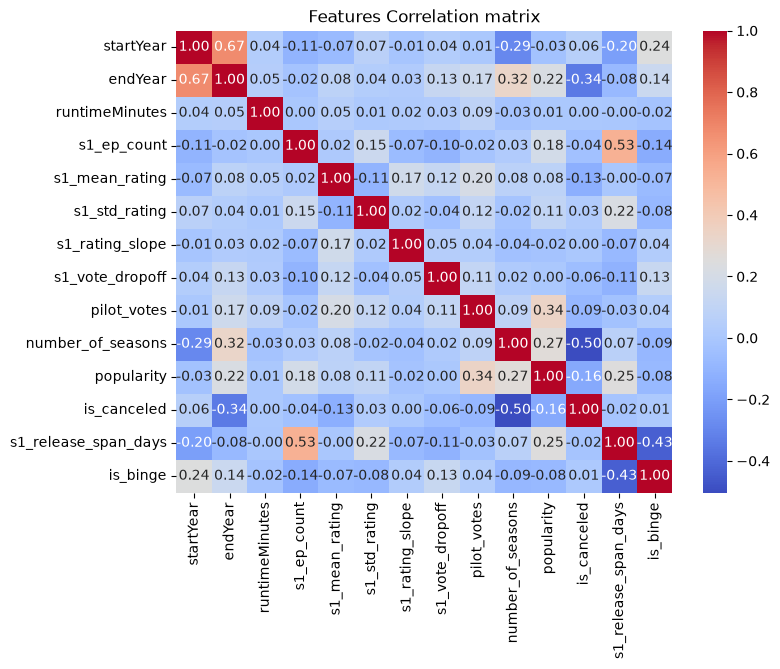

In [46]:
plt.figure(figsize=(8,6))
corr_matrix = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr_matrix, annot = True, cmap = "coolwarm", fmt = ".2f", linewidths=0)
plt.title("Features Correlation matrix")
plt.show()

### Correlation Matrix Insights

The **Target Drivers (is_canceled)**: shows a strong negative correlation with number_of_seasons (-0.50) and endYear (-0.34). Higher s1_mean_rating (-0.13), so it decreases (a bit) the likelihood of cancellation.
**Release Strategy:** is_binge and s1_release_span_days display a strong inverse correlation (-0.43), validating the binge vs. weekly feature logic.
**Independence:** Engineered features (drop-off, slope) show low linear correlation with each other, minimizing multicollinearity for the models.

In [54]:
# target and features

y = df["is_canceled"]

X = df.drop(columns = ["is_canceled","endYear","number_of_seasons",
                       "titleType","originalTitle","genres","networks"]).copy()

In [62]:
# Split and scale the data
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.25, stratify = y, random_state = 42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [63]:
# Prepare the model
logr = LogisticRegression(max_iter =  1000)
logr.fit(X_train_scaled,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [65]:
# Predictions
y_pred = logr.predict(X_test_scaled)
y_prob = logr.predict_proba(X_test_scaled)[::,1]

Text(0.5, 427.9555555555555, 'Predicted label')

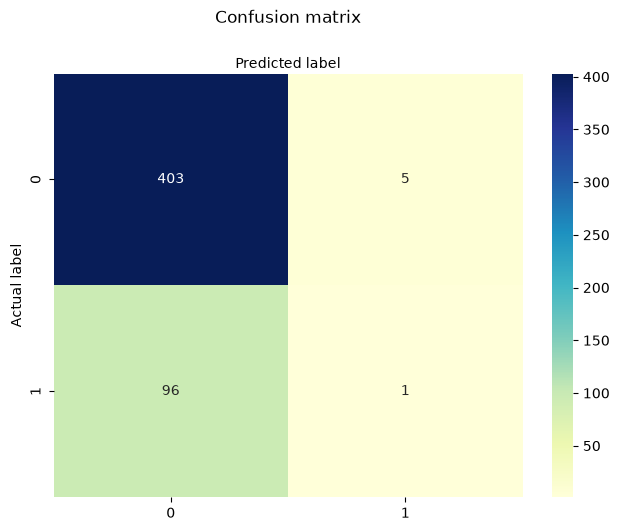

In [82]:
# Confusion matrix

cnf_matrix = confusion_matrix(y_test,y_pred)

class_names = [0,1]
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
sns.heatmap(pd.DataFrame(cnf_matrix), annot = True, cmap="YlGnBu", fmt = "g")
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')


In [83]:

print(classification_report(y_test,y_pred, target_names=["Not Canceled","Canceled"]))

              precision    recall  f1-score   support

Not Canceled       0.81      0.99      0.89       408
    Canceled       0.17      0.01      0.02        97

    accuracy                           0.80       505
   macro avg       0.49      0.50      0.45       505
weighted avg       0.68      0.80      0.72       505



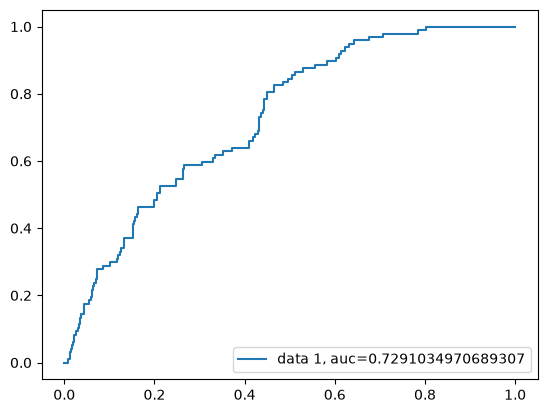

In [87]:
fpr, tpr, _ = roc_curve(y_test,  y_prob)
auc = roc_auc_score(y_test, y_prob)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()

In [89]:
# XGB Boos
xgb_model = XGBClassifier(scale_pos_weight = 9,
                             random_state = 41,
                             eval_metric = "logloss")

xgb_model.fit(X_train_scaled, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [90]:
# Predictions

y_pred_xgb = xgb_model.predict(X_test_scaled)
y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:,1]

Text(0.5, 427.9555555555555, 'Predicted label')

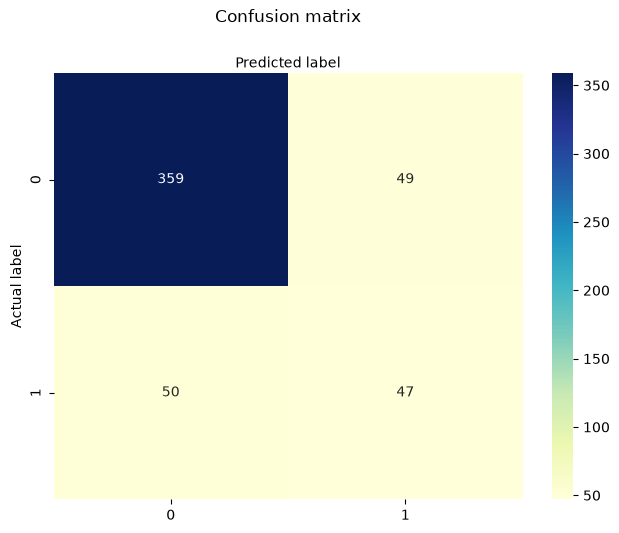

In [91]:
# Confusion matrix

cnf_matrix_xgb = confusion_matrix(y_test,y_pred_xgb)

class_names = ["A","B"]
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
sns.heatmap(pd.DataFrame(cnf_matrix_xgb), annot = True, cmap="YlGnBu", fmt = "g")
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')

In [92]:
print(classification_report(y_test,y_pred_xgb, target_names=["Not Canceled","Canceled"]))

              precision    recall  f1-score   support

Not Canceled       0.88      0.88      0.88       408
    Canceled       0.49      0.48      0.49        97

    accuracy                           0.80       505
   macro avg       0.68      0.68      0.68       505
weighted avg       0.80      0.80      0.80       505



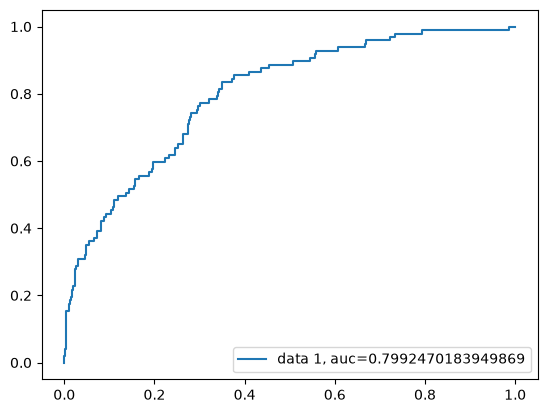

In [93]:
fpr, tpr, _ = roc_curve(y_test,  y_prob_xgb)
auc = roc_auc_score(y_test, y_prob_xgb)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()

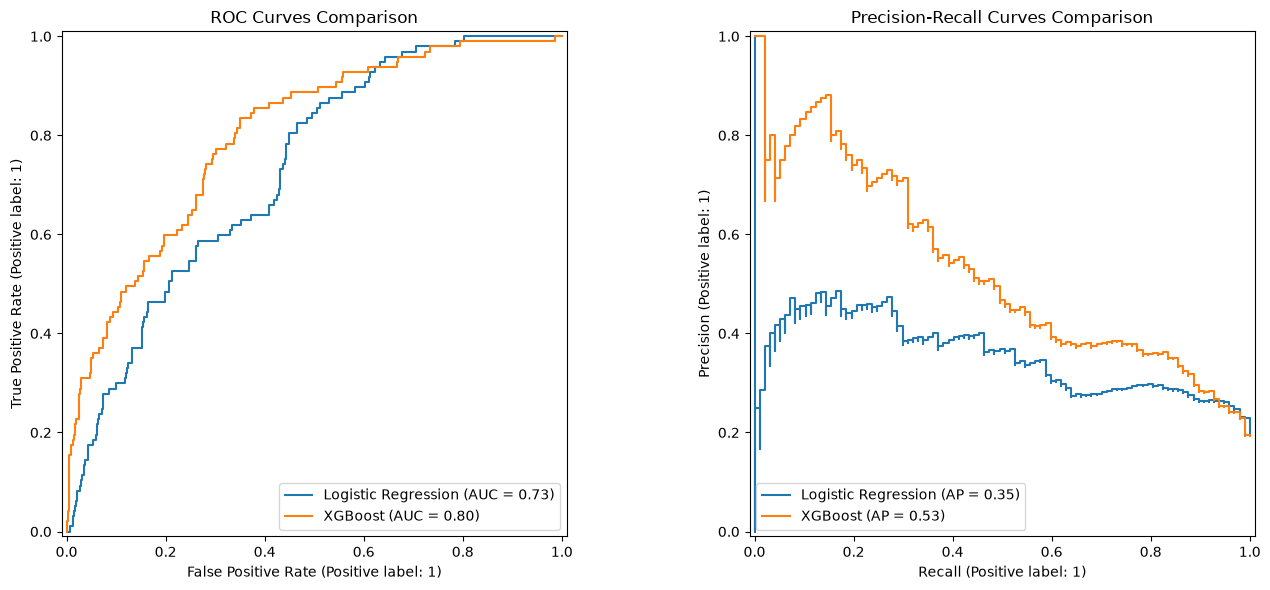

In [99]:
# Comparison of the 2 models

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Curva ROC a confronto
RocCurveDisplay.from_estimator(logr, X_test_scaled, y_test, ax=axes[0], name="Logistic Regression")
RocCurveDisplay.from_estimator(xgb_model, X_test_scaled, y_test, ax=axes[0], name="XGBoost")
axes[0].set_title("ROC Curves Comparison")

# Curva Precision-Recall a confronto (chiave per classi sbilanciate)
PrecisionRecallDisplay.from_estimator(logr, X_test_scaled, y_test, ax=axes[1], name="Logistic Regression")
PrecisionRecallDisplay.from_estimator(xgb_model, X_test_scaled, y_test, ax=axes[1], name="XGBoost")
axes[1].set_title("Precision-Recall Curves Comparison")

plt.tight_layout()
plt.show()


### Results & Conclusions

* **Model Performance Comparison:** 
  * **XGBoost** outperformed the Logistic Regression baseline significantly, achieving a **ROC-AUC of 0.80** (vs. 0.73) and an Average Precision of **0.53** (vs. 0.35) on the Precision-Recall curve.
* Due to the inherent skewness of the dataset (majority of shows survive past Season 1), Precision-Recall metrics proved critical in evaluating true predictive power over minority class cancellations.
* Non-linear interactions between audience engagement drop-offs, episode volume, and platform release strategies heavily influence early cancellation risks. XGBoost successfully captured these complex patterns.